# Classifying Birds vs. Planes using PyTorch and CIFAR-10

This notebook explores loading, visualizing, and normalizing image data using PyTorch's `torchvision` modules. We build and train a simple fully connected neural network (multi-layer perceptron) to distinguish between **airplanes** and **birds** in the CIFAR-10 dataset.

In [ ]:
import os
from torchvision import datasets

## 1. Setup and Data Loading
We begin by checking our working directory, defining our storage path, and downloading the CIFAR-10 dataset using `torchvision.datasets`.

In [ ]:
cwd = os.getcwd()
print(cwd)

C:\Users\Shivachetan Ulavi\DeepLearningProjects\ch5


In [ ]:
data_path = "../data-unversioned/CIFAR/"

In [ ]:
print(data_path)

../data-unversioned/CIFAR/


In [ ]:
cifar10 = datasets.CIFAR10(data_path, train=True, download= True)
cifar10_val = datasets.CIFAR10(data_path, train=False, download=True)

Using downloaded and verified file: ../data-unversioned/CIFAR/cifar-10-python.tar.gz
Extracting ../data-unversioned/CIFAR/cifar-10-python.tar.gz to ../data-unversioned/CIFAR/
Files already downloaded and verified


In [ ]:
type(cifar10).__mro__

(torchvision.datasets.cifar.CIFAR10,
 torchvision.datasets.vision.VisionDataset,
 torch.utils.data.dataset.Dataset,
 typing.Generic,
 object)

In [ ]:
len(cifar10)

50000

In [ ]:
class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

## 2. Exploring and Visualizing the Dataset
Let's extract an image from our dataset, inspect its properties, and display it using `matplotlib`.

In [ ]:
import matplotlib.pyplot as plt

img, label = cifar10[95]
img, label, class_names[label]

(<PIL.Image.Image image mode=RGB size=32x32>, 6, 'frog')

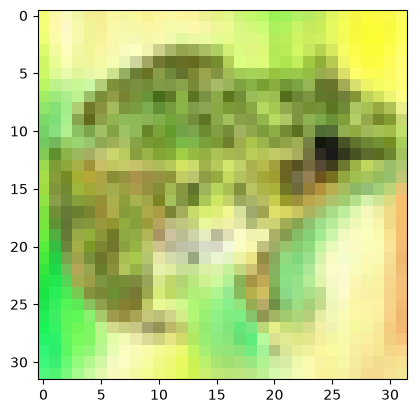

In [ ]:
plt.imshow(img)
plt.show()

In [ ]:
from torchvision import transforms
dir(transforms)

['AugMix',
 'AutoAugment',
 'AutoAugmentPolicy',
 'CenterCrop',
 'ColorJitter',
 'Compose',
 'ConvertImageDtype',
 'ElasticTransform',
 'FiveCrop',
 'GaussianBlur',
 'Grayscale',
 'InterpolationMode',
 'Lambda',
 'LinearTransformation',
 'Normalize',
 'PILToTensor',
 'Pad',
 'RandAugment',
 'RandomAdjustSharpness',
 'RandomAffine',
 'RandomApply',
 'RandomAutocontrast',
 'RandomChoice',
 'RandomCrop',
 'RandomEqualize',
 'RandomErasing',
 'RandomGrayscale',
 'RandomHorizontalFlip',
 'RandomInvert',
 'RandomOrder',
 'RandomPerspective',
 'RandomPosterize',
 'RandomResizedCrop',
 'RandomRotation',
 'RandomSolarize',
 'RandomVerticalFlip',
 'Resize',
 'TenCrop',
 'ToPILImage',
 'ToTensor',
 'TrivialAugmentWide',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '_functional_pil',
 '_functional_tensor',
 '_presets',
 'autoaugment',
 'functional',
 'transforms']

## 3. Transforming and Normalizing the Dataset
To prepare the images for our neural network, we convert them into PyTorch tensors and compute the mean and standard deviation across the dataset to perform channel-wise normalization.

In [ ]:
to_tensor = transforms.ToTensor()
img_t = to_tensor(img)
img_t.shape

torch.Size([3, 32, 32])

In [ ]:
tensor_cifar10 = datasets.CIFAR10(data_path, train=True, download=False, transform=transforms.ToTensor())

In [ ]:
img_t, _ = tensor_cifar10[95]
type(img_t)

torch.Tensor

In [ ]:
img_t.shape, img_t.type

(torch.Size([3, 32, 32]), <function Tensor.type>)

In [ ]:
img_t.min(), img_t.max()

(tensor(0.0392), tensor(1.))

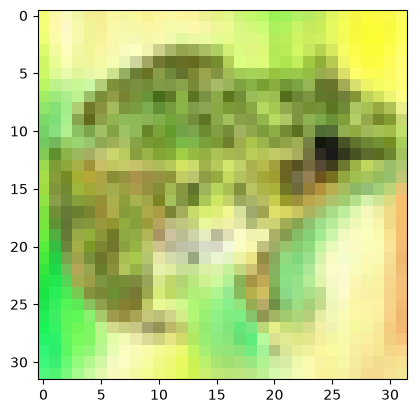

In [ ]:
plt.imshow(img_t.permute(1,2,0))
plt.show()

Normalizing the CIFAR10 dataset by mean and standard deviation

In [ ]:
import torch
imgs = torch.stack([img_t for img_t, _ in tensor_cifar10], dim=3)
imgs.shape

torch.Size([3, 32, 32, 50000])

In [ ]:
imgs.view(3,-1).mean(dim = 1)

tensor([0.4914, 0.4822, 0.4465])

In [ ]:
imgs.view(3,-1).std(dim = 1)

tensor([0.2470, 0.2435, 0.2616])

In [ ]:
transforms.Normalize((0.4914, 0.4822, 0.4465),(0.2470, 0.2435, 0.2616))

Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))

In [ ]:
transformed_cifar10 = datasets.CIFAR10(
    data_path, train=True, download=False,
    transform= transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465),
                             (0.2470, 0.2435, 0.2616))
    ])
)

In [ ]:
transformed_cifar10_val = datasets.CIFAR10(
    data_path, train=False, download=False,
    transform= transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465),
                             (0.2470, 0.2435, 0.2616))
    ])
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7195683..2.1264887].


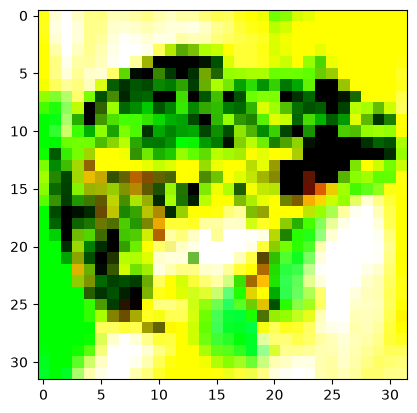

In [ ]:
img_t, _ = transformed_cifar10[95]
plt.imshow(img_t.permute(1,2,0))
plt.show()

Building the dataset to classify birds from planes

In [ ]:
label_map = {0:0, 2:1}
class_names = ['airplane', 'bird']
cifar2 = [(img, label_map[label])
         for img,label in transformed_cifar10
         if label in [0,2]]
cifar2_val = [(img, label_map[label])
             for img, label in transformed_cifar10_val
             if label in [0,2]]

In [ ]:
len(cifar2)

10000

In [ ]:
len(cifar2_val)

2000

## 4. Designing our Neural Network
We define a sequential model with a hidden layer utilizing `Tanh` activation and outputting log-probabilities via `LogSoftmax` for binary classification (airplane vs. bird).

In [ ]:
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.Tanh(),
    nn.Linear(512,2),
    nn.Softmax(dim=1)
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9574819..2.110384].


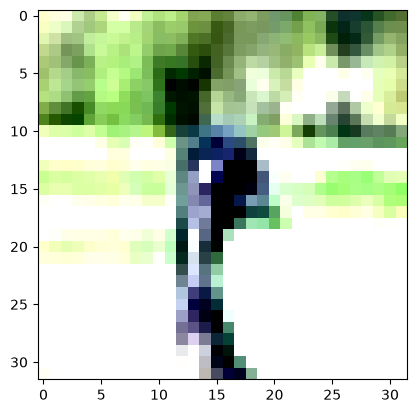

In [ ]:
img, _ = cifar2[10]
plt.imshow(img.permute(1,2,0))
plt.show() ##A random bird

In [ ]:
#cifar2[10]

Running the model on this image of the bird

In [ ]:
img_batch = img.view(-1).unsqueeze(0)
print(img_batch.shape)

torch.Size([1, 3072])


In [ ]:
out = model(img_batch)
out

tensor([[0.5332, 0.4668]], grad_fn=<SoftmaxBackward0>)

In [ ]:
_, index = torch.max(out, dim=1)
index

tensor([0])

In [ ]:
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.Tanh(),
    nn.Linear(512,2),
    nn.LogSoftmax(dim=1)
)

loss = nn.NLLLoss()

img, label = cifar2[10]
out = model(img.view(-1).unsqueeze(0))
loss(out, torch.tensor([label]))

tensor(0.6868, grad_fn=<NllLossBackward0>)

In [ ]:
del img, label

## 5. Model Training (Stochastic Gradient Descent)
First, we train our model using a standard loop passing one sample at a time on the device.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.Tanh(),
    nn.Linear(512, 2),
    nn.LogSoftmax(dim=1)).to(device)

learning_rate = 1e-2

optimizer = optim.SGD(model.parameters(), lr=learning_rate)

loss_fn = nn.NLLLoss()

n_epochs = 100

for epoch in range(n_epochs):
    for img, label in cifar2:
        # Move image and flatten/unsqueeze
        img = img.to(device)
        out = model(img.view(-1).unsqueeze(0))

        # Move label tensor to device
        label_tensor = torch.tensor([label], device=device)
        loss = loss_fn(out, label_tensor)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print("Epoch: %d, Loss: %f" % (epoch, float(loss)))

Epoch: 0, Loss: 5.480611
Epoch: 1, Loss: 5.880713
Epoch: 2, Loss: 10.659718
Epoch: 3, Loss: 4.525036
Epoch: 4, Loss: 8.444011
Epoch: 5, Loss: 0.563365
Epoch: 6, Loss: 6.912476
Epoch: 7, Loss: 9.471234
Epoch: 8, Loss: 8.152678
Epoch: 9, Loss: 7.085780
Epoch: 10, Loss: 12.634377
Epoch: 11, Loss: 7.786944
Epoch: 12, Loss: 11.748102
Epoch: 13, Loss: 8.701757
Epoch: 14, Loss: 4.873537
Epoch: 15, Loss: 7.055629
Epoch: 16, Loss: 7.389684
Epoch: 17, Loss: 14.254038
Epoch: 18, Loss: 12.281646
Epoch: 19, Loss: 12.777983
Epoch: 20, Loss: 15.426066
Epoch: 21, Loss: 13.139387
Epoch: 22, Loss: 6.174707
Epoch: 23, Loss: 12.032763
Epoch: 24, Loss: 8.873233
Epoch: 25, Loss: 12.251596
Epoch: 26, Loss: 6.569525
Epoch: 27, Loss: 10.653959
Epoch: 28, Loss: 2.554265
Epoch: 29, Loss: 8.815033
Epoch: 30, Loss: 14.141000
Epoch: 31, Loss: 4.784079
Epoch: 32, Loss: 4.791863
Epoch: 33, Loss: 12.716143
Epoch: 34, Loss: 16.071262
Epoch: 35, Loss: 15.405766
Epoch: 36, Loss: 8.853729
Epoch: 37, Loss: 9.837130
Epoch: 

Using DataLoader to train in mini-batches

### Training with Mini-Batches using `DataLoader`
To speed up and stabilize training, we employ PyTorch's `DataLoader` to train our network on batches of size 64.

In [ ]:
train_loader = torch.utils.data.DataLoader(cifar2, batch_size=64, shuffle=True)


model = nn.Sequential(
            nn.Linear(3072, 128),
            nn.Tanh(),
            nn.Linear(128, 2),
            nn.LogSoftmax(dim=1)).to(device)

learning_rate = 1e-2

optimizer = optim.SGD(model.parameters(), lr=learning_rate)

loss_fn = nn.NLLLoss()

n_epochs = 100

for epoch in range(n_epochs):
    for imgs, labels in train_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)


        outputs = model(imgs.view(imgs.shape[0], -1))
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print("Epoch: %d, Loss: %f" % (epoch, float(loss)))

Epoch: 0, Loss: 0.606005
Epoch: 1, Loss: 0.308727
Epoch: 2, Loss: 0.381543
Epoch: 3, Loss: 0.394769
Epoch: 4, Loss: 0.437394
Epoch: 5, Loss: 0.382625
Epoch: 6, Loss: 0.346192
Epoch: 7, Loss: 0.507004
Epoch: 8, Loss: 0.531553
Epoch: 9, Loss: 0.231851
Epoch: 10, Loss: 0.712292
Epoch: 11, Loss: 0.161138
Epoch: 12, Loss: 0.407016
Epoch: 13, Loss: 0.186940
Epoch: 14, Loss: 0.391629
Epoch: 15, Loss: 0.323892
Epoch: 16, Loss: 0.225084
Epoch: 17, Loss: 0.163817
Epoch: 18, Loss: 0.332428
Epoch: 19, Loss: 0.264969
Epoch: 20, Loss: 0.502025
Epoch: 21, Loss: 0.202943
Epoch: 22, Loss: 0.399293
Epoch: 23, Loss: 0.297928
Epoch: 24, Loss: 0.528401
Epoch: 25, Loss: 0.191264
Epoch: 26, Loss: 0.214663
Epoch: 27, Loss: 0.249796
Epoch: 28, Loss: 0.233764
Epoch: 29, Loss: 0.100249
Epoch: 30, Loss: 0.163948
Epoch: 31, Loss: 0.152499
Epoch: 32, Loss: 0.271601
Epoch: 33, Loss: 0.151965
Epoch: 34, Loss: 0.169334
Epoch: 35, Loss: 0.049116
Epoch: 36, Loss: 0.146961
Epoch: 37, Loss: 0.105763
Epoch: 38, Loss: 0.217

In [ ]:
val_loader = torch.utils.data.DataLoader(cifar2_val, batch_size=64, shuffle=False)

correct = 0
total = 0

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model(imgs.view(imgs.shape[0], -1))
        _, predicted = torch.max(outputs, dim=1)
        total += labels.shape[0]
        correct += int((predicted == labels).sum())
    print("Accuracy: %f" % (correct / total))



Accuracy: 0.816500


## 6. Model Evaluation
Let's measure the performance of our trained model on the unseen validation dataset.

In [ ]:
numel_list = [p.numel() for p in model.parameters()
             if p.requires_grad == True]
sum(numel_list), numel_list

(393602, [393216, 128, 256, 2])

## Conclusion

While we achieved a decent validation accuracy (~81%), this approach of using a fully connected (sequential) model on flattened images has severe structural limitations:

1. **Lack of Translation Invariance:** Fully connected neural networks treat pixels at different locations as completely independent features. If an object shifts by just a few pixels, the flattened 1D representation changes completely, making it hard for the model to generalize.
2. **Spatial Correlation Loss:** Flattening a 2D image ($32 \times 32 \times 3$) into a 1D vector ($3072$) discards the natural spatial relationships between neighboring pixels.
3. **Overfitting to Training Positions:** Our model essentially "memorizes" the precise 1D input vectors and pixel locations of the training set rather than learning abstract features.

To overcome these limitations and build models that are translation invariant, we must transition from fully connected layers to **Convolutional Neural Networks (CNNs)**.